# 02 — Price elasticity

**Question:** if a product's shelf price drops by 1 %, by how much do its unit sales rise, and whose sales does it take?

**Model** — one log-log regression per product, on the modelling table `weekly_panel`:

$$\log(\text{units}_{s,t}) = \beta \, \log(\text{price}_{s,t}) + \gamma' \text{promo}_{s,t} + \delta' \text{competition}_{s,t} + \alpha_s + \text{season}_t + \varepsilon_{s,t}$$

- $\beta$ is the **own-price elasticity**: a 1 % price change moves units by $\beta$ %.
- promo: feature, display, promotion in the previous and next week.
- competition: other brands' average discount and share on feature/display; share of the brand's other products on promotion.
- $\alpha_s$: store fixed effects (store size, location, clientele).
- season: month, holiday and pre-holiday weeks, linear trend.

Code: `src/promo_pricing/elasticity.py`, tested in `tests/test_elasticity.py`.

In [1]:
import sys
sys.path.insert(0, "../src")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from promo_pricing.elasticity import (
    load_panel, fit_own_elasticities, shrink_to_category,
    brand_cross_elasticities, volume_multiplier, breakeven_margin,
)

DB = "../data/frat.duckdb"
FIG = "../reports/figures/"
pd.set_option("display.width", 200)

CAT_ORDER = ["FROZEN PIZZA", "COLD CEREAL", "ORAL HYGIENE PRODUCTS", "BAG SNACKS"]
CAT_LABEL = {"COLD CEREAL": "Cold cereal", "FROZEN PIZZA": "Frozen pizza",
             "BAG SNACKS": "Pretzels", "ORAL HYGIENE PRODUCTS": "Mouthwash"}
# same colour per category as in notebook 01
CAT_COLOR = {"COLD CEREAL": "#2a78d6", "FROZEN PIZZA": "#eb6834", "BAG SNACKS": "#1baf7a", "ORAL HYGIENE PRODUCTS": "#eda100"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "legend.frameon": False,
})

df = load_panel(DB)
print(f"{len(df):,} rows, {df.upc.nunique()} products, {df.store_id.nunique()} stores")

524,741 rows, 55 products, 77 stores


## 1. Where does the price variation come from?

An elasticity is estimated from price **changes**. Before choosing the controls, check which changes the data contains: are prices cut in all stores the same week (a chain-wide promotion calendar), or store by store?

In [2]:
d = df[["upc", "category", "store_id", "week", "state", "log_price"]].copy()
d["within_series"] = d.log_price - d.groupby(["upc", "store_id"]).log_price.transform("mean")
d["common_week"] = d.groupby(["upc", "week"]).within_series.transform("mean")
d["common_state_week"] = d.groupby(["upc", "state", "week"]).within_series.transform("mean")

decomp = d.groupby("category").apply(lambda g: pd.Series({
    "share_common_to_all_stores_pct": 100 * g.common_week.var() / g.within_series.var(),
    "share_common_within_state_pct": 100 * g.common_state_week.var() / g.within_series.var(),
}), include_groups=False).round(0)
decomp.index = decomp.index.map(CAT_LABEL)
decomp

,share_common_to_all_stores_pct,share_common_within_state_pct
category,,
Pretzels,59.0,68.0
Cold cereal,77.0,86.0
Frozen pizza,82.0,94.0
Mouthwash,84.0,91.0


**Most price movements are identical in every store the same week**: 77 % to 84 % for cereal, pizza and mouthwash, 59 % for pretzels, and 68 % to 94 % within a state. Promotions follow a chain-wide calendar.

This drives the choice of specification:
- **Week fixed effects** (one dummy per week) would remove every chain-wide demand shock, but also most of the price variation. The elasticity would then rest on the small store-specific differences, which are noisier, and noise in a regressor biases the estimate toward zero.
- **Main specification:** keep the chain-wide price changes and control for the demand shocks that could coincide with them: month, the six major US holidays and the week before each, a trend, and competitors' promotions. The remaining risk is that promotions are scheduled in weeks of unusually high demand that these controls miss, which would make elasticities look larger than they are.

Both are estimated: the true value should lie between the two.

## 2. Own-price elasticity per product

In [3]:
main = shrink_to_category(fit_own_elasticities(df, spec="time"))
week_fe = fit_own_elasticities(df, spec="week_fe")
res = main.merge(week_fe[["upc", "elasticity"]].rename(columns={"elasticity": "elasticity_week_fe"}), on="upc")

print("Negative elasticities:", (res.elasticity < 0).sum(), "of", len(res))
print("Significant at 5 %:   ", (res.ci_high < 0).sum(), "of", len(res))
res[["category", "description", "n_obs", "elasticity", "ci_low", "ci_high",
     "elasticity_shrunk", "elasticity_week_fe"]].sort_values(["category", "elasticity"]).round(2)

Negative elasticities: 55 of 55
Significant at 5 %:    55 of 55


,category,description,n_obs,elasticity,ci_low,ci_high,elasticity_shrunk,elasticity_week_fe
48,BAG SNACKS,SNYDR FF MINI PRETZELS,10606,-1.91,-2.18,-1.65,-1.82,-0.71
20,BAG SNACKS,RLDGLD PRETZEL STICKS,11306,-1.61,-1.96,-1.26,-1.50,-0.81
47,BAG SNACKS,SNYDR SOURDOUGH NIBBLERS,10089,-1.55,-1.81,-1.29,-1.49,-0.92
46,BAG SNACKS,SNYDR PRETZEL RODS,10991,-1.55,-2.02,-1.07,-1.37,-1.62
19,BAG SNACKS,RLDGLD TINY TWISTS PRTZL,11557,-1.34,-1.79,-0.88,-1.21,-0.09
39,BAG SNACKS,MKSL PRETZEL STICKS,4450,-1.27,-1.72,-0.81,-1.15,1.59
38,BAG SNACKS,MKSL DUTCH PRETZELS,4542,-1.19,-1.62,-0.76,-1.10,-0.70
37,BAG SNACKS,MKSL MINI TWIST PRETZELS,4744,-1.18,-1.67,-0.68,-1.06,2.41
18,BAG SNACKS,RLDGLD BRAIDED HONEY WHT,9258,-1.15,-1.52,-0.77,-1.08,-0.53
0,BAG SNACKS,PL MINI TWIST PRETZELS,11938,-0.70,-0.88,-0.52,-0.70,-0.79


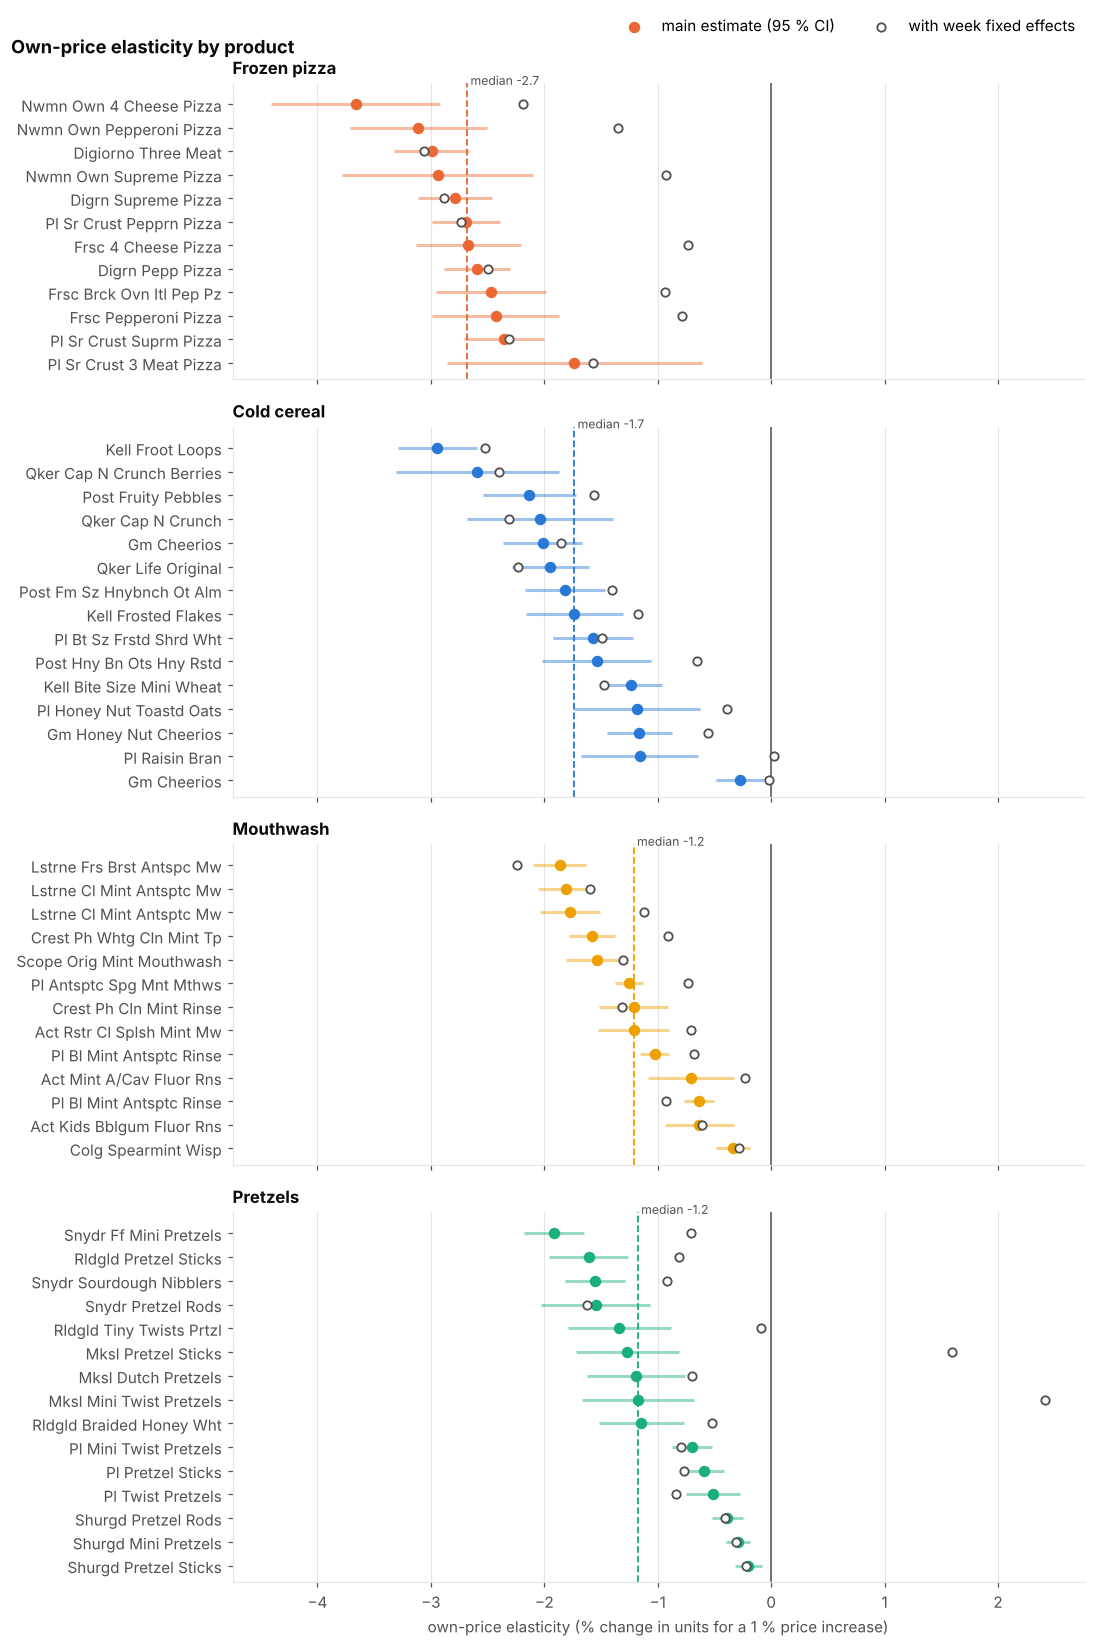

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(10, 15), sharex=True,
                         gridspec_kw={"height_ratios": [res.category.eq(c).sum() for c in CAT_ORDER]})
for ax, cat in zip(axes, CAT_ORDER):
    g = res[res.category == cat].sort_values("elasticity", ascending=False).reset_index(drop=True)
    y = np.arange(len(g))
    col = CAT_COLOR[cat]
    ax.hlines(y, g.ci_low, g.ci_high, color=col, lw=2, alpha=0.45)
    ax.scatter(g.elasticity, y, color=col, s=42, zorder=3, label="main estimate (95 % CI)")
    ax.scatter(g.elasticity_week_fe, y, facecolor="white", edgecolor=INK2, s=30, lw=1.2, zorder=3,
               label="with week fixed effects")
    med = g.elasticity.median()
    ax.axvline(med, color=col, lw=1.2, ls="--")
    ax.text(med, len(g) - 0.3, f" median {med:.1f}", color=INK2, fontsize=8, va="bottom")
    ax.set_yticks(y, g.description.str.title())
    ax.set_title(CAT_LABEL[cat])
    ax.axvline(0, color=INK2, lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_ylim(-0.7, len(g) - 0.1)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.0))
axes[-1].set_xlabel("own-price elasticity (% change in units for a 1 % price increase)")
fig.suptitle("Own-price elasticity by product", x=0.01, ha="left", fontweight="bold", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIG + "04_own_price_elasticity.png", bbox_inches="tight")

**Findings**
- **All 55 elasticities are negative and statistically significant**: demand falls when price rises, for every product.
- **Frozen pizza is the most price-sensitive category** (median −2.7): a 10 % price cut raises units by about 30 %. Cereal follows (−1.7); mouthwash and pretzels are less sensitive (−1.2).
- **Private label is less elastic than the leading national brands** in pretzels (−0.5 to −0.7 against −1.2 to −1.9 for Snyder's and Rold Gold) and mouthwash (−0.6 to −1.3 against −1.2 to −1.9 for Listerine, Crest and Scope): its buyers come for the low regular price, not for promotions. Small niche brands (Shultz pretzels, Colgate Wisp) are the least elastic of all. In pizza and cereal, private label is about as elastic as the brands.
- With week fixed effects (hollow markers), elasticities are smaller in absolute value, as expected from section 1, but the ranking of categories is the same. For the three MKSL pretzels, sold only in 34 stores of the Ohio region, these estimates even turn positive: once chain-wide changes are removed, too little reliable price variation is left for them.

## 3. Robustness

The median elasticity per category under four variants. A conclusion is credible only if it survives all of them.

In [5]:
flags_ok = df[(df.flag_price_above_base == 0) & (df.flag_visits_gt_units == 0)]
no_flag = fit_own_elasticities(flags_ok, spec="time")

rob = pd.DataFrame({
    "main": res.groupby("category").elasticity.median(),
    "shrunk to category": res.groupby("category").elasticity_shrunk.median(),
    "without flagged rows": no_flag.groupby("category").elasticity.median(),
    "week fixed effects": res.groupby("category").elasticity_week_fe.median(),
}).loc[CAT_ORDER].rename(index=CAT_LABEL).round(2)
rob

,main,shrunk to category,without flagged rows,week fixed effects
category,,,,
Frozen pizza,-2.68,-2.69,-2.68,-1.88
Cold cereal,-1.74,-1.70,-1.73,-1.47
Mouthwash,-1.21,-1.20,-1.21,-0.91
Pretzels,-1.18,-1.08,-1.17,-0.70


- **Flagged rows** (price above base, more baskets than units — 0.8 % of the data) do not change the results.
- **Shrinkage** pulls the noisiest product estimates toward their category mean, which matters for products sold in few stores; medians barely move, which shows that no single noisy product drives the category picture.
- **Week fixed effects** give a lower bound. The ranking pizza > cereal > mouthwash ≈ pretzels holds in every variant.

## 4. Promotion dynamics

Does a promotion steal sales from the following week (shoppers stock up), and do shoppers wait for an announced promotion?

In [6]:
dyn = res.groupby("category")[["feature_effect", "display_effect", "post_promo_effect", "pre_promo_effect"]].median()
(100 * dyn.loc[CAT_ORDER].rename(index=CAT_LABEL)).round(1).add_suffix(" (%)")

,feature_effect (%),display_effect (%),post_promo_effect (%),pre_promo_effect (%)
category,,,,
Frozen pizza,25.9,48.4,-1.8,3.4
Cold cereal,42.1,51.8,-1.9,4.3
Mouthwash,25.0,12.4,0.8,2.9
Pretzels,25.4,36.5,0.5,4.3


- **Feature and display add volume on top of the price cut**: median +12 % (mouthwash display) to +52 % (cereal display). Part of the raw "×5" lift of notebook 01 was the price cut itself.
- **No measurable post-promotion dip**: the week after a promotion sells about the same as a normal week (−2 % to +1 %). For these categories at weekly store level, promotions do not mainly pull forward future purchases, which makes them more valuable than a pantry-loading story would suggest.
- The week **before** a promotion sells 3–4 % more. A plausible cause is calendar overlap: weeks end on Wednesday, so a promotion starting mid-week is partly recorded in the preceding week.

## 5. Cross-price elasticities between brands

Brand-level model: units of brand *i* regressed on the prices of every brand in the category (same controls). A **positive** value in row *i*, column *j* means that when brand *j* raises its price, brand *i* sells more: they are **substitutes**.

Frozen pizza — elasticities (row: sales of, column: price of)
               KING  PRIVATE LABEL  TOMBSTONE  TONYS
KING          -3.20          -0.24       0.33   0.14
PRIVATE LABEL -0.17          -2.88       0.85   0.08
TOMBSTONE     -0.16           0.05      -2.66   0.11
TONYS         -0.58           0.14       0.65  -3.01

Cold cereal — elasticities (row: sales of, column: price of)
               GENERAL MI  KELLOGG  POST FOODS  PRIVATE LABEL  QUAKER
GENERAL MI          -0.83     0.20        0.10          -0.00   -0.02
KELLOGG              0.16    -2.49        0.42           0.46    0.05
POST FOODS           0.10    -0.36       -2.00           0.78    0.11
PRIVATE LABEL        0.20     0.23        0.49          -0.83   -0.01
QUAKER              -0.20    -0.29       -2.01          -2.03   -2.04

Mouthwash — elasticities (row: sales of, column: price of)
               CHATTEM  COLGATE  P & G  PRIVATE LABEL  WARNER
CHATTEM          -0.97     0.11  -0.10          -0.02   -0.02
COLGATE

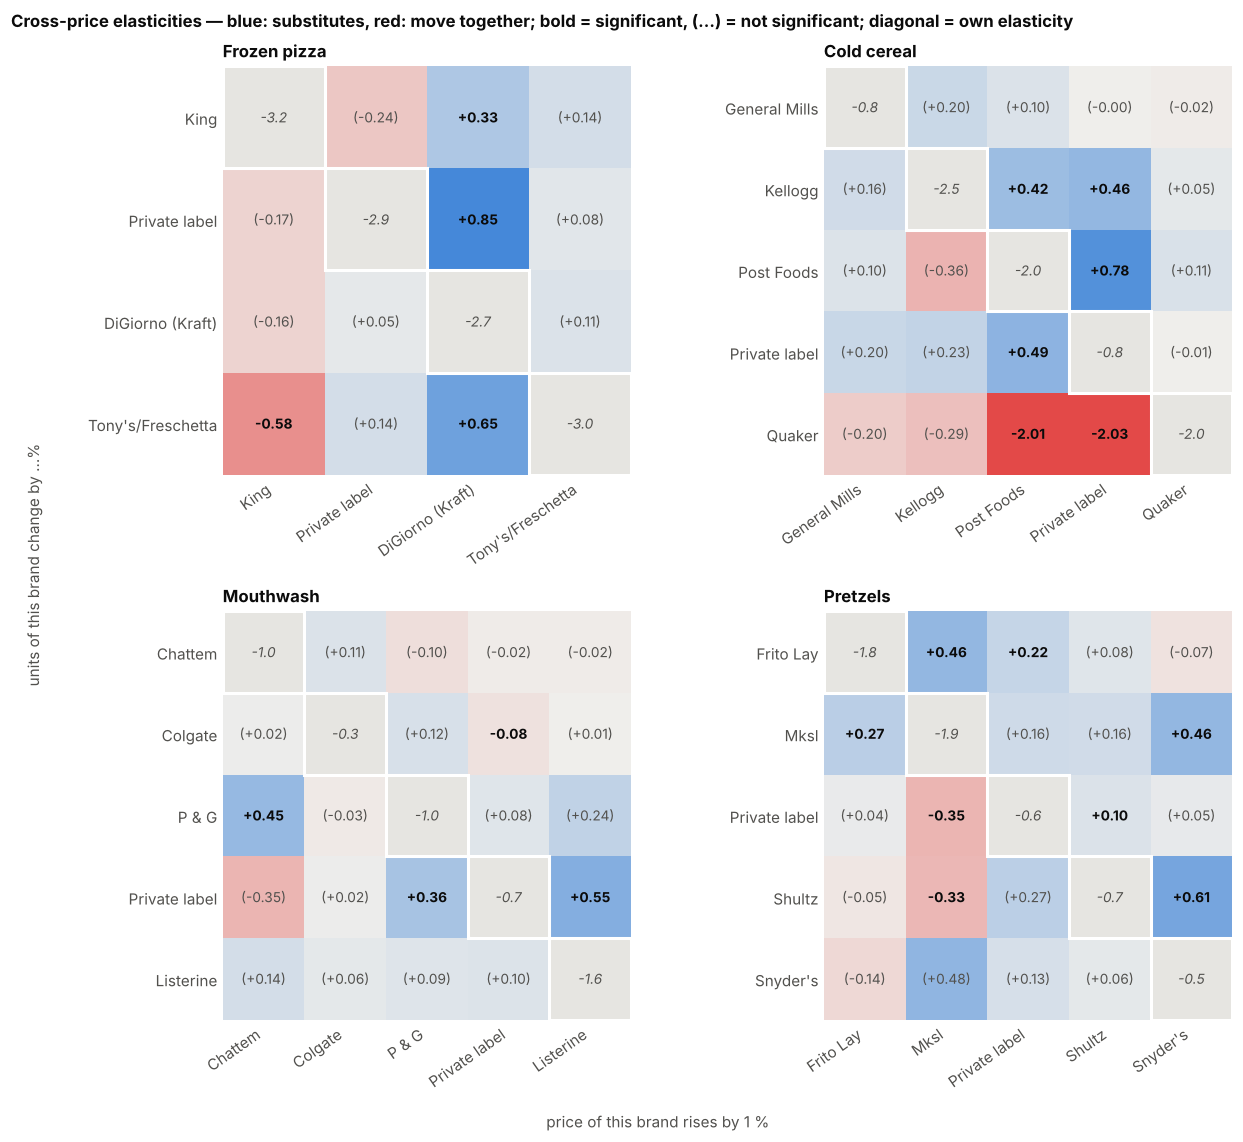

In [7]:
cross = {cat: brand_cross_elasticities(DB, cat) for cat in CAT_ORDER}
for cat in CAT_ORDER:
    print(CAT_LABEL[cat], "— elasticities (row: sales of, column: price of)")
    print(cross[cat][0].round(2).to_string(), end="\n\n")

cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])  # red (-) / gray / blue (+)
fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))
for ax, cat in zip(axes.flat, CAT_ORDER):
    E, T = cross[cat]
    M = E.values.copy()
    off = ~np.eye(len(E), dtype=bool)
    shown = np.where(off, M, np.nan)
    ax.imshow(shown, cmap=cmap, vmin=-1, vmax=1)
    for i in range(len(E)):
        for j in range(len(E)):
            if i == j:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, facecolor="#e6e5e1", edgecolor="white", lw=2))
                ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9, color=INK2, style="italic")
            else:
                sig = abs(T.values[i, j]) >= 2
                txt = f"{M[i, j]:+.2f}" if sig else f"({M[i, j]:+.2f})"
                ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                        color=INK if sig else INK2, fontweight="bold" if sig else "normal")
    names = [n.title().replace("Private Label", "Private label").replace("General Mi", "General Mills").replace("Snyder S", "Snyder's")
             .replace("Tombstone", "DiGiorno (Kraft)").replace("Warner", "Listerine").replace("Tonys", "Tony's/Freschetta") for n in E.index]
    ax.set_xticks(range(len(E)), names, rotation=35, ha="right")
    ax.set_yticks(range(len(E)), names)
    ax.set_title(CAT_LABEL[cat])
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
fig.supxlabel("price of this brand rises by 1 %", color=INK2, fontsize=10)
fig.supylabel("units of this brand change by …%", color=INK2, fontsize=10)
fig.suptitle("Cross-price elasticities — blue: substitutes, red: move together; bold = significant, (…) = not significant; diagonal = own elasticity",
             x=0.01, ha="left", fontweight="bold", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(FIG + "05_cross_price_elasticity.png", bbox_inches="tight")

**Findings**
- **DiGiorno is the price reference in frozen pizza.** A 10 % DiGiorno price increase lifts private-label pizza by about 8.5 %, Tony's by 6.5 % and King by 3.3 %, while DiGiorno's own sales do not react significantly to any competitor's price.
- **Private label captures switching from the leaders.** A 10 % Listerine price increase lifts private-label mouthwash by 5.5 %, and Crest/Scope by 3.6 %. In cereal, Post, Kellogg and private label take sales from each other (for example, Post +10 % → private label +4.9 %, Kellogg +4.2 %).
- **Cheerios (General Mills) is insulated**: low own-price elasticity at brand level (−0.8) and no significant cross effect in either direction, a sign of strong loyalty.
- **Snyder's discounts mostly cannibalise Snyder's.** Its brand-level elasticity (−0.45) is far smaller than its product-level ones (−1.5 to −1.9): when one Snyder's product is discounted, most of the extra volume comes from the brand's other products. Measuring promotions product by product overstates what the brand gains.
- **Limit — a few significant negative values (red).** The largest is Quaker: its sales would rise when Post or private label cut their prices. Their prices are not correlated, so this is not collinearity; the likely cause is coordinated cereal-aisle events, where several brands are promoted together and the aisle traffic lifts every brand. Smaller negative values (Tony's vs King, private label and Shultz vs MKSL) may have similar causes. These cells should not be used for pricing decisions without more data, for example promotion calendars by aisle.

## 6. What it means for a pricing decision

A 10 % price cut always sells more units for an elastic product, but does it make more money? It depends on the gross margin. The **break-even margin** is the margin above which the cut increases gross profit:

$$\text{profit after} > \text{profit before} \iff (m - d)\,L > m \iff m > \frac{d\,L}{L-1}, \quad L = (1-d)^{\beta}$$

In [8]:
d_cut = 0.10
whatif = res.groupby("category").elasticity.median().loc[CAT_ORDER].to_frame("median_elasticity")
whatif["units_change_pct"] = 100 * (whatif.median_elasticity.apply(lambda e: volume_multiplier(e, -d_cut)) - 1)
whatif["revenue_change_pct"] = 100 * ((1 - d_cut) * (1 + whatif.units_change_pct / 100) - 1)
whatif["breakeven_gross_margin_pct"] = 100 * whatif.median_elasticity.apply(lambda e: breakeven_margin(e, d_cut))
whatif.rename(index=CAT_LABEL).round(1)

,median_elasticity,units_change_pct,revenue_change_pct,breakeven_gross_margin_pct
category,,,,
Frozen pizza,-2.7,32.6,19.4,40.6
Cold cereal,-1.7,20.1,8.1,59.8
Mouthwash,-1.2,13.6,2.3,83.4
Pretzels,-1.2,13.2,1.9,85.8


- **Frozen pizza:** a 10 % cut lifts units by 33 % and revenue by 19 %. It raises gross profit as long as the gross margin is above about 40 %.
- **Cereal:** units +20 %, revenue +8 %; profitable only above a ~60 % gross margin.
- **Mouthwash and pretzels:** units +13 to 14 %, revenue +2 %. The cut pays off only if the gross margin exceeds about 85 %. In practice, **a plain price cut on these categories mostly gives margin away**; their promotional money is better spent on display and feature, which add volume without lowering the price.

These are *gross* margins on the regular price, for the retailer or the brand depending on who funds the discount, and without the cost of the display or circular itself. Notebook 03 adds these costs to compute the return on each promotion.

## Summary

| | Frozen pizza | Cereal | Mouthwash | Pretzels |
|---|---|---|---|---|
| Median own-price elasticity | −2.7 | −1.7 | −1.2 | −1.2 |
| 10 % price cut → units | +33 % | +20 % | +14 % | +13 % |
| Break-even gross margin | ~40 % | ~60 % | ~83 % | ~86 % |
| Who gains when the leader raises its price | private label, Tony's | private label, Post, Kellogg | private label | Shultz (from Snyder's) |

**Limits:** estimates rely on time variation within a chain-wide promotion calendar (section 1), so they could be somewhat overstated if promotions are timed on unobserved demand peaks; the week-fixed-effects estimates give the lower bound. Elasticities are assumed constant across discount depths and stores.

**Next:** notebook 03 — baseline vs incremental volume per promotion, and promotion ROI.